# Multi-dataset image-segmentation experiments

> **Research project:** Unsupervised image segmentation of ionized regions in simulated 21-cm tomographic data during the Epoch of Reionization (EoR).

## Notebook purpose

Main experimental notebook containing entropy enhancement, unsharp masking, Gaussian smoothing, FFT filtering, local thresholding, morphology and watershed experiments. References multiple FITS datasets.

## Research context

The experiments investigate image-processing approaches for identifying candidate ionized (H II) structures in 21-cm brightness-temperature slices. The work compares local-entropy enhancement, unsharp masking, Gaussian smoothing, Fourier-domain low-pass filtering, local thresholding, morphological cleanup and watershed-based region partitioning.

## How to use this notebook

1. Run in Google Colab or a local Jupyter environment.
2. Install the packages listed in `requirements.txt`.
3. Obtain the FITS input dataset(s) described in `docs/datasets.md` and update file paths where needed.
4. Run cells in order. Some cells reuse variables created earlier in the notebook.
5. Treat displayed masks as algorithm outputs; physical interpretation requires checking the mask convention and, where available, comparison with simulation truth.

## Reproducibility notes

- Original code cells and saved outputs are retained in this annotated copy.
- The original downloaded notebook is preserved under `archive/originals/`.
- This notebook has not been represented as independently validated or fully reproducible; file paths, array shapes, parameter choices and execution order should be checked before rerunning.

---


### Unsharp masking
Enhance local edges by adding a scaled high-frequency residual to a smoothed image. Inspect the `radius` and `amount` settings because sharpening can amplify noise and create halos.


In [ ]:
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
from skimage.filters.rank import entropy
from skimage.morphology import disk
from skimage import exposure
from skimage.util import img_as_ubyte
from skimage import data
from skimage.filters import unsharp_mask
from skimage import filters as ski
from skimage import filters, exposure, morphology

........................................................................................................................................................

Now with the pipeline we have built we implement the first pipeline to original image

........................................................................................................................................................

### Input data: FITS loading
Load the FITS file and inspect/extract the data array. Confirm the HDU, axis order, selected slice index and resulting 2-D shape before interpreting the image.


In [ ]:
hdul2 = fits.open('HI_CUBE_z_7.859.fits')
cosmo_data2 = np.squeeze(hdul2[0].data)
cosmo_1 = cosmo_data2[:, :, 51]
cosmo_1.shape





(256, 256)

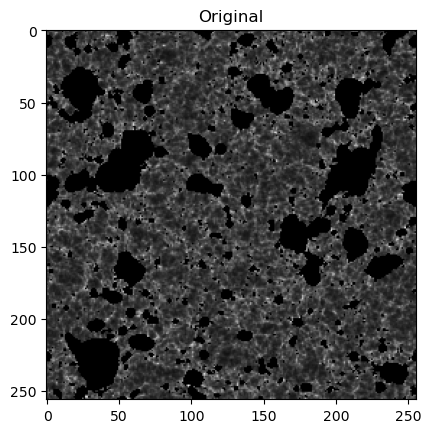

In [ ]:
plt.imshow(cosmo_1, cmap='gray'); plt.title("Original")
plt.show()

### Histogram diagnostics
Compare pixel-value distributions before and after processing. Histograms describe intensity distributions; by themselves they do not validate physical recovery of H II regions.


In [ ]:
plt.hist(cosmo_1.flatten(), bins=50); plt.title("Original")
plt.show()

Here we observe clear bimodal peak

SyntaxError: invalid syntax (4021858793.py, line 4)

### Local entropy enhancement
Calculate neighbourhood entropy using a disk-shaped footprint. This measures local texture/variation, not ionization directly; intensity rescaling and footprint radius affect the result.


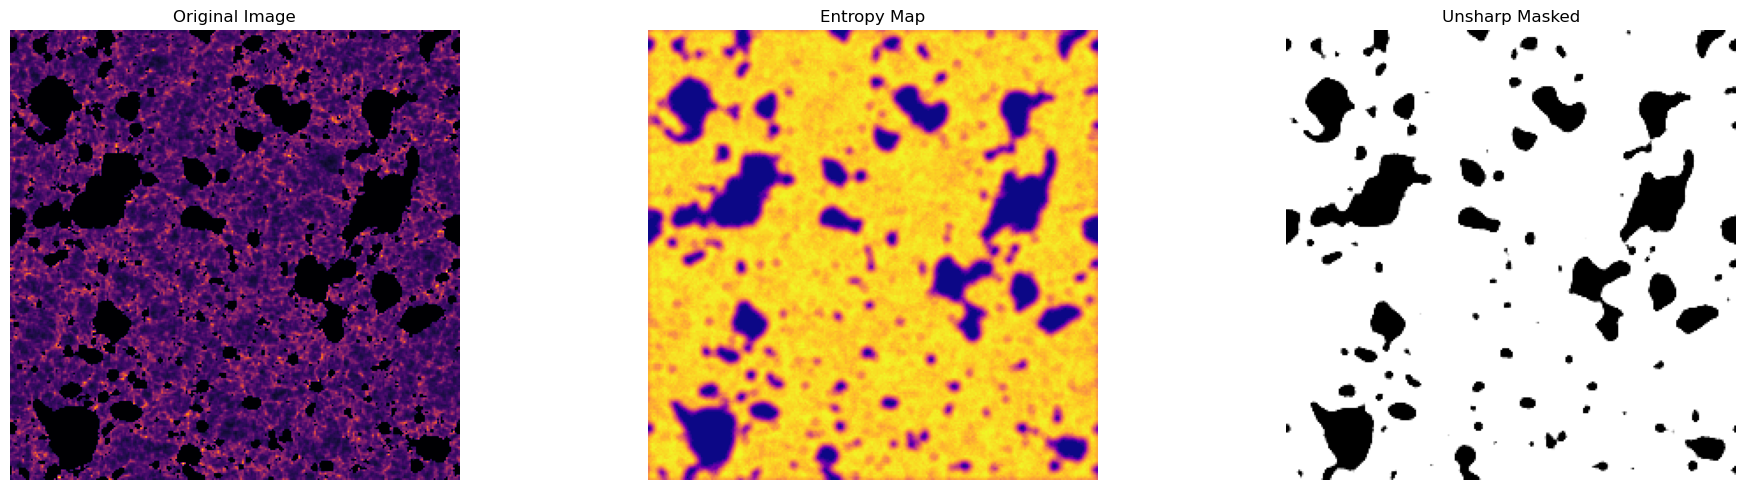

In [ ]:
image1 = cosmo_1  # Dummy brightness temperature map

# --- 2. Apply Local Entropy ---
entropy_input = img_as_ubyte(exposure.rescale_intensity(image1))
entropy_map1 = entropy(entropy_input, morphology.disk(3))

# --- 3. Apply Unsharp Masking to sharpen edges ---
sharpened1 = unsharp_mask(entropy_map1, radius=20, amount=1)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].imshow(image1, cmap='inferno')
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].imshow(entropy_map1, cmap='plasma')
axes[1].set_title("Entropy Map")
axes[1].axis('off')

axes[2].imshow(sharpened1, cmap='gray')
axes[2].set_title("Unsharp Masked")
axes[2].axis('off')

plt.tight_layout()
plt.show()

### Unsharp masking
Enhance local edges by adding a scaled high-frequency residual to a smoothed image. Inspect the `radius` and `amount` settings because sharpening can amplify noise and create halos.


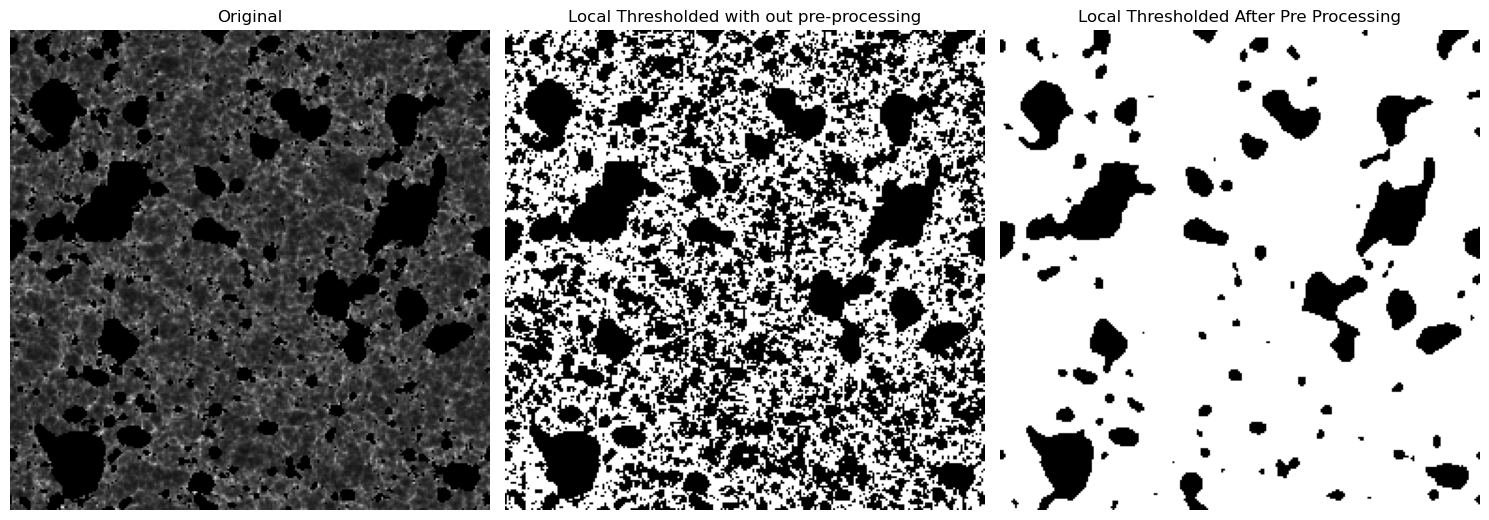

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_local
from skimage import io  # or use your cosmo_1

# Assuming cosmo_1 is your 2D image from a z-slice
# Make sure it's float type for proper thresholding
image1 = cosmo_1.astype(float)
unsharp1 = sharpened1.astype(float)

# Set block size for local thresholding (must be odd)
block_size = 121  # you can also use it with values like 31, 51, 101
offset = 0  # adjust if needed to shift the threshold

# Compute the local threshold map
local_thresh = threshold_local(image1, block_size, offset=offset)
local_thresh2 = threshold_local(unsharp1, block_size, offset=offset)

# Apply threshold: pixels > local threshold → foreground (True)
binary_local = image1 > local_thresh
binary_local21 = unsharp1 > local_thresh2
# Plot original and thresholded image
fig, ax = plt.subplots(1, 3, figsize=(15, 10))
plt.gray()

ax[0].imshow(image1)
ax[0].set_title("Original")

ax[1].imshow(binary_local)
ax[1].set_title("Local Thresholded with out pre-processing")

ax[2].imshow(binary_local21)
ax[2].set_title("Local Thresholded After Pre Processing")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()


### Unsharp masking
Enhance local edges by adding a scaled high-frequency residual to a smoothed image. Inspect the `radius` and `amount` settings because sharpening can amplify noise and create halos.


In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(image1, cmap='Spectral')
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].imshow(entropy_map1, cmap='Spectral')
axes[1].set_title("Entropy Map")
axes[1].axis('off')

axes[2].imshow(sharpened1, cmap='Spectral')
axes[2].set_title("Unsharp Masked")
axes[2].axis('off')

axes[3].imshow(binary_local2, cmap='gray')
axes[3].set_title("Segmented image")
axes[3].axis('off')

plt.tight_layout()
plt.show()

........................................................................................................................................................

APPLYING THE SAME TECHNIQUE FOR CORRUPTED MAP WITH INSTRUMENTAL AND FOREGROUND NOISE

........................................................................................................................................................

### Input data: FITS loading
Load the FITS file and inspect/extract the data array. Confirm the HDU, axis order, selected slice index and resulting 2-D shape before interpreting the image.


In [ ]:
hdul1 = fits.open('SKA_AA4_r2km_z_7.391__4.33arcmin_3.97arcmin_cube.fits')
cosmo_data1 = np.squeeze(hdul1[0].data)
cosmo_2 = cosmo_data1[:, :, 51]
cosmo_2.shape

(32, 170)

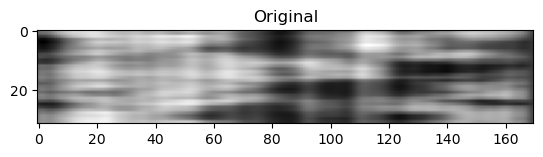

In [ ]:
plt.imshow(cosmo_2, cmap='gray'); plt.title("Original")
plt.show()

### Local entropy enhancement
Calculate neighbourhood entropy using a disk-shaped footprint. This measures local texture/variation, not ionization directly; intensity rescaling and footprint radius affect the result.


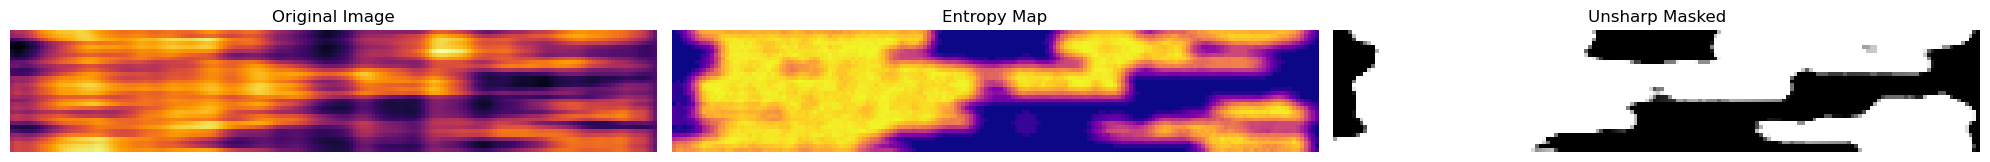

In [ ]:
image2 = cosmo_2  # Dummy brightness temperature map

# --- 2. Apply Local Entropy ---
entropy_input = img_as_ubyte(exposure.rescale_intensity(image2))
entropy_map2 = entropy(entropy_input, morphology.disk(3))

# --- 3. Apply Unsharp Masking to sharpen edges ---
sharpened2 = unsharp_mask(entropy_map2, radius=20, amount=1)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].imshow(image2, cmap='inferno')
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].imshow(entropy_map2, cmap='plasma')
axes[1].set_title("Entropy Map")
axes[1].axis('off')

axes[2].imshow(sharpened2, cmap='gray')
axes[2].set_title("Unsharp Masked")
axes[2].axis('off')

plt.tight_layout()
plt.show()

### Unsharp masking
Enhance local edges by adding a scaled high-frequency residual to a smoothed image. Inspect the `radius` and `amount` settings because sharpening can amplify noise and create halos.


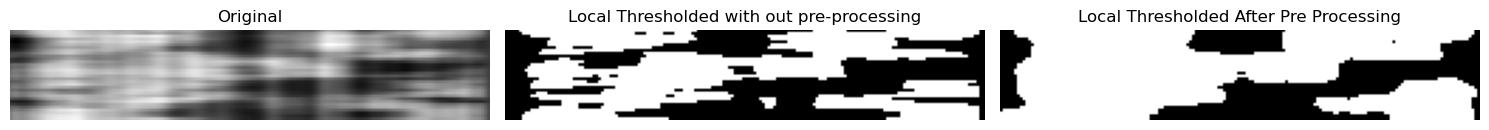

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_local
from skimage import io  # or use your cosmo_1

# Assuming cosmo_1 is your 2D image from a z-slice
# Make sure it's float type for proper thresholding
image2 = cosmo_2.astype(float)
unsharp2 = sharpened2.astype(float)

# Set block size for local thresholding (must be odd)
block_size = 121  # you can experiment with values like 31, 51, 101
offset = 0  # adjust if needed to shift the threshold

# Compute the local threshold map
local_thresh = threshold_local(image2, block_size, offset=offset)
local_thresh2 = threshold_local(unsharp2, block_size, offset=offset)

# Apply threshold: pixels > local threshold → foreground (True)
binary_local = image2 > local_thresh
binary_local22 = unsharp2> local_thresh2
# Plot original and thresholded image
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
plt.gray()

ax[0].imshow(image2)
ax[0].set_title("Original")

ax[1].imshow(binary_local)
ax[1].set_title("Local Thresholded with out pre-processing")

ax[2].imshow(binary_local22)
ax[2].set_title("Local Thresholded After Pre Processing")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()


### Unsharp masking
Enhance local edges by adding a scaled high-frequency residual to a smoothed image. Inspect the `radius` and `amount` settings because sharpening can amplify noise and create halos.


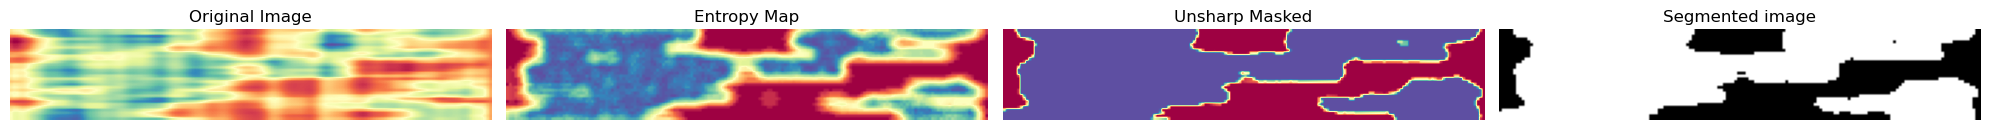

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(image2, cmap='Spectral')
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].imshow(entropy_map2, cmap='Spectral')
axes[1].set_title("Entropy Map")
axes[1].axis('off')

axes[2].imshow(sharpened2, cmap='Spectral')
axes[2].set_title("Unsharp Masked")
axes[2].axis('off')

axes[3].imshow(binary_local22, cmap='gray')
axes[3].set_title("Segmented image")
axes[3].axis('off')

plt.tight_layout()
plt.show()

...............................................................................................................................

APPLYING THE SAME TECHNIQUE TO ANOTHER CORRUPTED FILE - DIFFUSE IMAGES

.................................................................................................................................

### Input data: FITS loading
Load the FITS file and inspect/extract the data array. Confirm the HDU, axis order, selected slice index and resulting 2-D shape before interpreting the image.


In [ ]:
hdul3 = fits.open('SKA_AA4_TRECS-Diffuse_2HR_10S_z_7.391_cube.fits')
cosmo_data3 = np.squeeze(hdul3[0].data)
cosmo_3 = cosmo_data3[:, :, 51]
cosmo_3.shape

(256, 202)

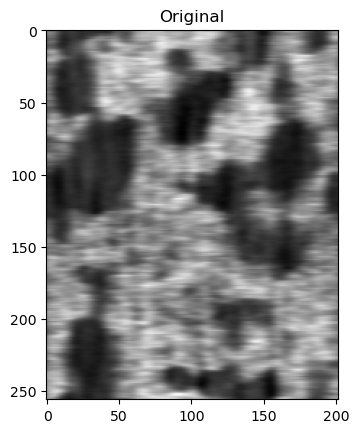

In [ ]:
plt.imshow(cosmo_3, cmap='gray'); plt.title("Original")
plt.show()

### Local entropy enhancement
Calculate neighbourhood entropy using a disk-shaped footprint. This measures local texture/variation, not ionization directly; intensity rescaling and footprint radius affect the result.


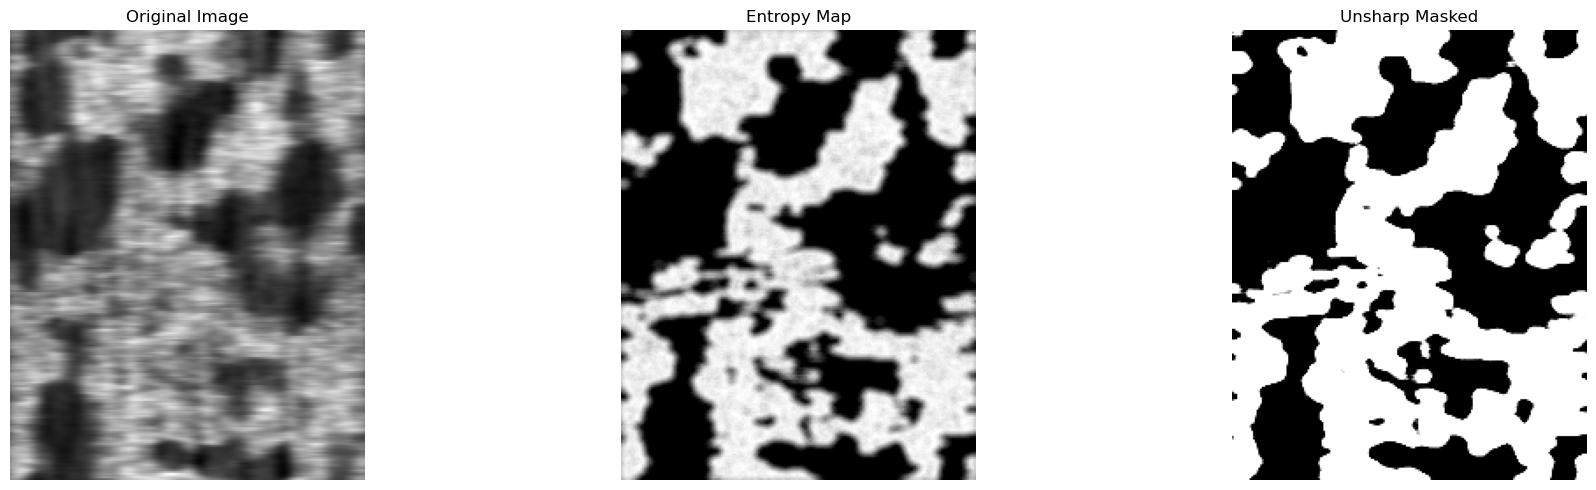

In [ ]:
image3 = cosmo_3  # brightness temperature map

# --- 2. Apply Local Entropy ---
entropy_input = img_as_ubyte(exposure.rescale_intensity(image3))
entropy_map3 = entropy(entropy_input, morphology.disk(3))

# --- 3. Apply Unsharp Masking to sharpen edges ---
sharpened3 = unsharp_mask(entropy_map3, radius=20, amount=1)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].imshow(image3, cmap='gray')
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].imshow(entropy_map3, cmap='gray')
axes[1].set_title("Entropy Map")
axes[1].axis('off')

axes[2].imshow(sharpened3, cmap='gray')
axes[2].set_title("Unsharp Masked")
axes[2].axis('off')

plt.tight_layout()
plt.show()

### Unsharp masking
Enhance local edges by adding a scaled high-frequency residual to a smoothed image. Inspect the `radius` and `amount` settings because sharpening can amplify noise and create halos.


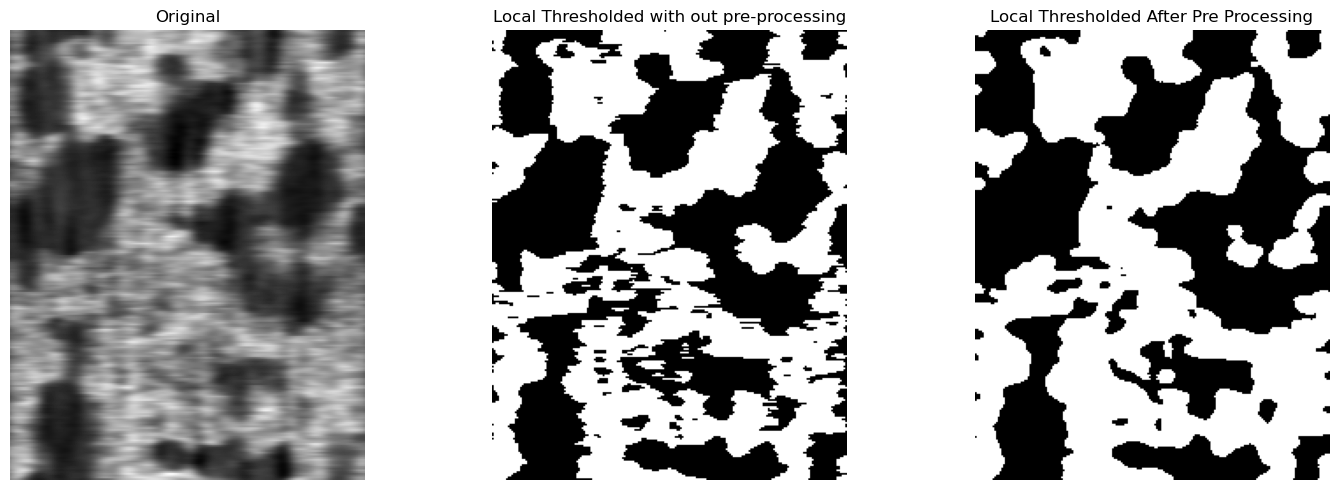

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_local
from skimage import io  # or use your cosmo_1

# Assuming cosmo_1 is your 2D image from a z-slice
# Make sure it's float type for proper thresholding
image3 = cosmo_3.astype(float)
unsharp3 = sharpened3.astype(float)

# Set block size for local thresholding (must be odd)
block_size = 121  # you can experiment with values like 31, 51, 101
offset = 0  # adjust if needed to shift the threshold

# Compute the local threshold map
local_thresh = threshold_local(image3, block_size, offset=offset)
local_thresh2 = threshold_local(unsharp3, block_size, offset=offset)

# Apply threshold: pixels > local threshold → foreground (True)
binary_local = image3 > local_thresh
binary_local23 = unsharp3 > local_thresh2
# Plot original and thresholded image
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
plt.gray()

ax[0].imshow(image3)
ax[0].set_title("Original")

ax[1].imshow(binary_local)
ax[1].set_title("Local Thresholded with out pre-processing")

ax[2].imshow(binary_local23)
ax[2].set_title("Local Thresholded After Pre Processing")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()


### Unsharp masking
Enhance local edges by adding a scaled high-frequency residual to a smoothed image. Inspect the `radius` and `amount` settings because sharpening can amplify noise and create halos.


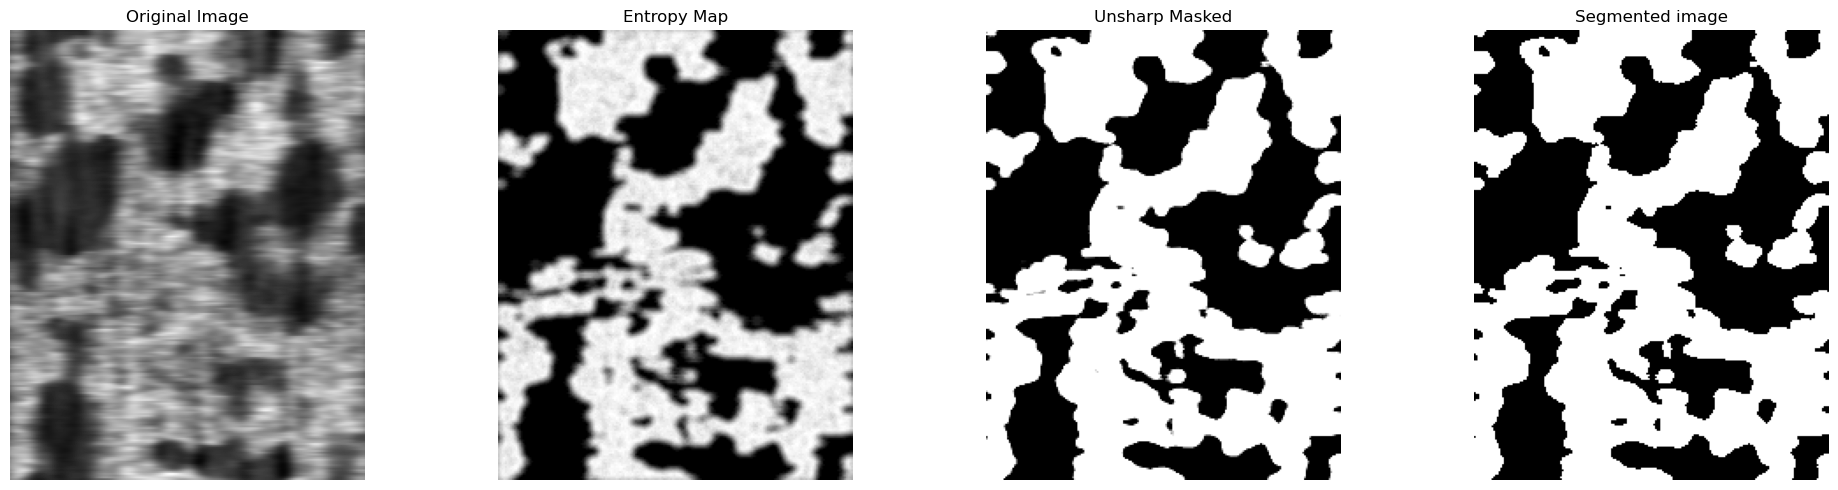

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(image3, cmap='gray')
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].imshow(entropy_map3, cmap='gray')
axes[1].set_title("Entropy Map")
axes[1].axis('off')

axes[2].imshow(sharpened3, cmap='gray')
axes[2].set_title("Unsharp Masked")
axes[2].axis('off')

axes[3].imshow(binary_local23, cmap='gray')
axes[3].set_title("Segmented image")
axes[3].axis('off')

plt.tight_layout()
plt.show()

........................................................................................................................................................

NOW TECHNIQUE 2 WILL BE APPLIED TO ALL THE DATA SETS

........................................................................................................................................................

DATA SET 1 - Original Image

Here we first apply gaussian to the original image. As the image is contains less noise the gaussian destroys the information.

### Gaussian smoothing
Apply Gaussian convolution to suppress small-scale fluctuations. The `sigma` parameter controls the smoothing scale; stronger smoothing can also erase genuine small structures.


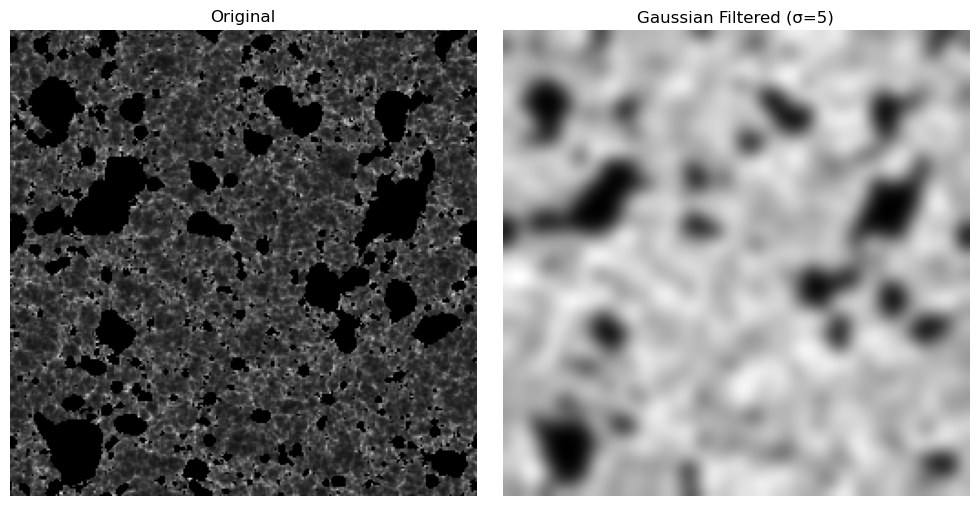

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage import data, img_as_float

# Load a sample image (you can replace this with your own image)
image1 = cosmo_1  # grayscale image

# Apply Gaussian filter
sigma = 5  # standard deviation, controls amount of blur
smoothed_image1 = gaussian_filter(image, sigma=sigma)

# Display
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image1, cmap='grey')
axes[0].set_title("Original")
axes[1].imshow(smoothed_image1, cmap='grey')
axes[1].set_title(f"Gaussian Filtered (σ={sigma})")

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()


### Local entropy enhancement
Calculate neighbourhood entropy using a disk-shaped footprint. This measures local texture/variation, not ionization directly; intensity rescaling and footprint radius affect the result.


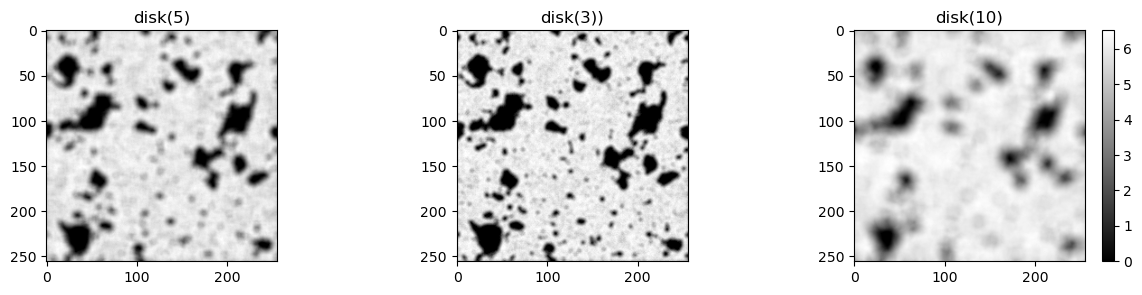

In [ ]:
import numpy as np

from skimage.filters.rank import entropy
from skimage.morphology import disk
from skimage import exposure
from skimage.util import img_as_ubyte

Cosmo_Entropy = img_as_ubyte(exposure.rescale_intensity(cosmo_1))
entropy_map1 = entropy(Cosmo_Entropy, disk(5))
entropy_map2 = entropy(Cosmo_Entropy, disk(3))
entropy_map3 = entropy(Cosmo_Entropy, disk(10))
plt.figure(figsize= (15,3))


plt.subplot(1,3,1); plt.imshow(entropy_map1, cmap='gray')
plt.title("disk(5)")
plt.subplot(1,3,2); plt.imshow(entropy_map2, cmap='gray')
plt.title("disk(3))")
plt.subplot(1,3,3); plt.imshow(entropy_map3,cmap='gray')
plt.title("disk(10)")

plt.colorbar()

plt.show()

Here we apply the FFT Low pass filter to the entropy image again as it is a original image the destroy the image information so the segmentation does not work well for this method.

### Fourier-domain filtering
Transform the image to Fourier space, apply a low-pass mask, and transform back. The cutoff/radius determines which spatial frequencies are retained; document it as a filtering choice, not guaranteed foreground removal.


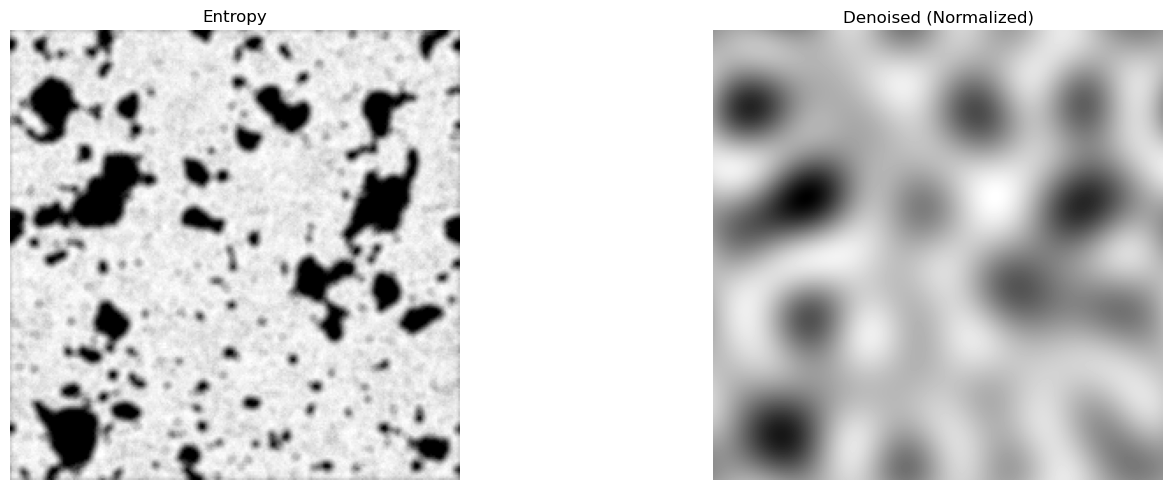

In [ ]:
#FFT FOR ENTROPY

import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft2, ifft2, fftshift, ifftshift
from skimage.util import invert
from skimage.exposure import rescale_intensity

def fft_low_pass_filter(entropy_map3, radius=20):
    # Step 1: Forward 2D FFT
    f_image = fft2(entropy_map2)
    f_shift = fftshift(f_image)  # Shift zero-freq to center

    # Step 2: Create circular low-pass filter mask
    rows, cols = image.shape
    crow, ccol = rows // 2, cols // 2
    y, x = np.ogrid[:rows, :cols]
    mask_area = (x - ccol)**2 + (y - crow)**2 <= radius**2
    mask = np.zeros_like(entropy_map2)
    mask[mask_area] = 1

    # Step 3: Apply mask
    f_filtered = f_shift * mask

    # Step 4: Inverse FFT to get denoised image
    f_ishift = ifftshift(f_filtered)
    denoised = np.abs(ifft2(f_ishift))

    return denoised, f_shift, f_filtered

# ---- Step 1: Apply FFT Filter ----
denoised_img, fft_original, fft_filtered = fft_low_pass_filter(entropy_map2, radius=5)

# ---- Step 2: Normalize ----
denoised_img_norm1 = rescale_intensity(denoised_img, in_range='image', out_range=(0, 1))

# ---- Step 3: Plot All Results ----
plt.figure(figsize=(16, 5))

plt.subplot(1, 2, 1)
plt.imshow(entropy_map2, cmap='gray')
plt.title("Entropy")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(denoised_img_norm1, cmap='gray')
plt.title("Denoised (Normalized)")
plt.axis('off')

plt.tight_layout()
plt.show()


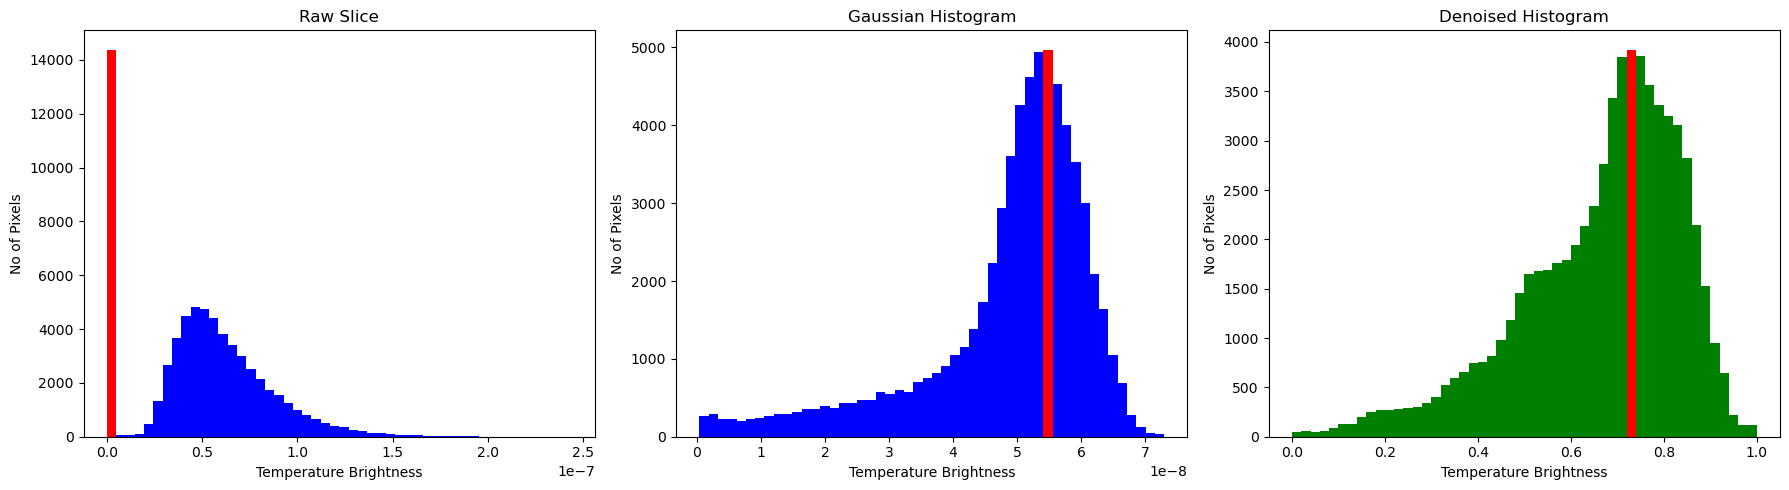

In [ ]:
# List of images and details
images = [cosmo_1, smoothed_image1, denoised_img_norm1]
titles = ["Raw Slice", "Gaussian Histogram", "Denoised Histogram"]
colors = ['blue', 'blue', 'green']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))

for i in range(3):
    data = images[i].flatten()
    counts, bins = np.histogram(data, bins=50)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    peak_idx = np.argmax(counts)

    # Set bar colors: highlight peak
    bar_colors = [colors[i]] * len(counts)
    bar_colors[peak_idx] = 'red'

    # Plot histogram with peak highlighted
    axes[i].bar(bin_centers, counts, width=np.diff(bins), color=bar_colors, align='center')
    axes[i].set_title(titles[i])
    axes[i].set_xlabel("Temperature Brightness")
    axes[i].set_ylabel("No of Pixels")

plt.tight_layout()
plt.savefig("Comparison_with_peaks.png", dpi=600, bbox_inches="tight")
plt.show()


This histogram clearly explains that by employing the filter techniques we lost the large scale strutures information. Therefore it affects segmentation.

### Local/adaptive thresholding
Compute a spatially varying threshold using a neighbourhood window. Check that `block_size` is odd and appropriate for the image dimensions, and record the offset because it changes the classified area.


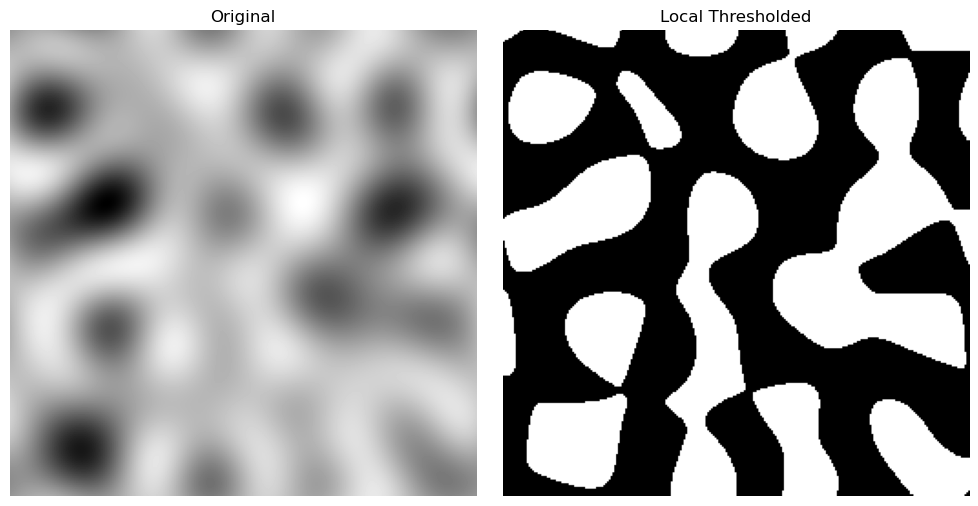

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_local
from skimage import io



# Set block size for local thresholding (must be odd)
block_size = 101  # you can experiment with values like 31, 51, 101
offset = 0  # adjust if needed to shift the threshold

# Compute the local threshold map
local_thresh = threshold_local(denoised_img_norm1, block_size, offset=offset)


# Apply threshold: pixels > local threshold → foreground (True)
binary_local24 = denoised_img_norm1 < local_thresh

# Plot original and thresholded image
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
plt.gray()

ax[0].imshow( denoised_img_norm1 , cmap='gray')
ax[0].set_title("Original")

ax[1].imshow(binary_local24)
ax[1].set_title("Local Thresholded")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()


Here thresholding doesn't works as you can see as the information is lost.

........................................................................................................................................................

Technique 2 is applied to corrupted images

........................................................................................................................................................

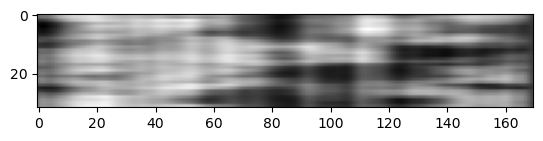

In [ ]:
plt.imshow(cosmo_2, cmap='gray')

### Histogram diagnostics
Compare pixel-value distributions before and after processing. Histograms describe intensity distributions; by themselves they do not validate physical recovery of H II regions.


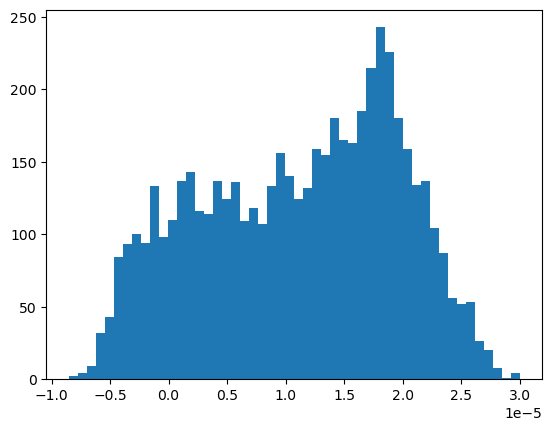

In [ ]:
plt.hist(cosmo_2.flatten(), bins=50)
plt.show()

### Gaussian smoothing
Apply Gaussian convolution to suppress small-scale fluctuations. The `sigma` parameter controls the smoothing scale; stronger smoothing can also erase genuine small structures.


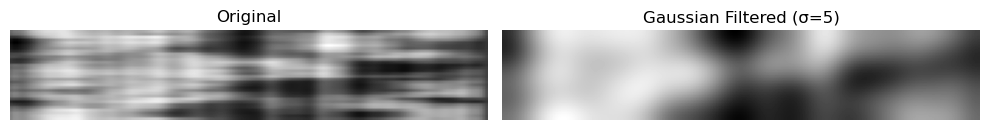

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage import data, img_as_float

# Load a sample image (you can replace this with your own image)
image2 = cosmo_2  # grayscale image

# Apply Gaussian filter
sigma = 5  # standard deviation, controls amount of blur
smoothed_image2 = gaussian_filter(image2, sigma=sigma)

# Display
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image2, cmap='grey')
axes[0].set_title("Original")
axes[1].imshow(smoothed_image2, cmap='grey')
axes[1].set_title(f"Gaussian Filtered (σ={sigma})")

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()


### Histogram diagnostics
Compare pixel-value distributions before and after processing. Histograms describe intensity distributions; by themselves they do not validate physical recovery of H II regions.


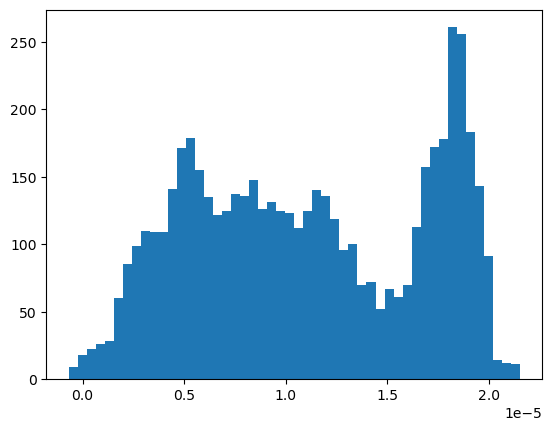

In [ ]:
plt.hist(smoothed_image2.flatten(), bins=50)
plt.show()

### Local entropy enhancement
Calculate neighbourhood entropy using a disk-shaped footprint. This measures local texture/variation, not ionization directly; intensity rescaling and footprint radius affect the result.


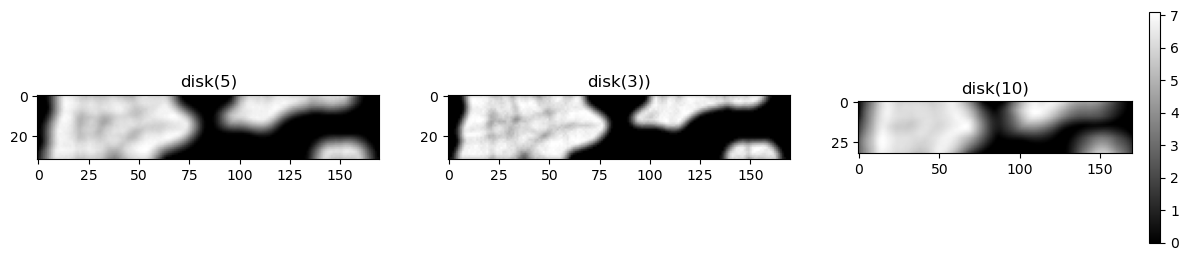

In [ ]:
import numpy as np

from skimage.filters.rank import entropy
from skimage.morphology import disk
from skimage import exposure
from skimage.util import img_as_ubyte

Cosmo_Entropy = img_as_ubyte(exposure.rescale_intensity(smoothed_image2))
entropy_map1 = entropy(Cosmo_Entropy, disk(5))
entropy_map2 = entropy(Cosmo_Entropy, disk(3))
entropy_map3 = entropy(Cosmo_Entropy, disk(10))
plt.figure(figsize= (15,3))


plt.subplot(1,3,1); plt.imshow(entropy_map1, cmap='gray')
plt.title("disk(5)")
plt.subplot(1,3,2); plt.imshow(entropy_map2, cmap='gray')
plt.title("disk(3))")
plt.subplot(1,3,3); plt.imshow(entropy_map3,cmap='gray')
plt.title("disk(10)")

plt.colorbar()

plt.show()

### Fourier-domain filtering
Transform the image to Fourier space, apply a low-pass mask, and transform back. The cutoff/radius determines which spatial frequencies are retained; document it as a filtering choice, not guaranteed foreground removal.


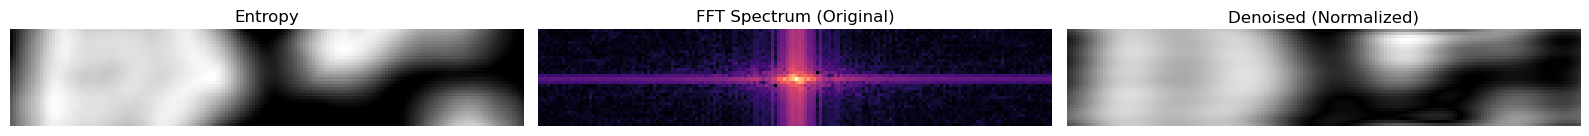

In [ ]:
# FFT FOR ENTROPY

import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft2, ifft2, fftshift, ifftshift
from skimage.util import invert
from skimage.exposure import rescale_intensity

def fft_low_pass_filter(entropy_map3, radius=20):
    # Step 1: Forward 2D FFT
    f_image = fft2(entropy_map3)
    f_shift = fftshift(f_image)  # Shift zero-freq to center

    # Step 2: Create circular low-pass filter mask
    rows, cols = entropy_map3.shape  # ✅ Fix here
    crow, ccol = rows // 2, cols // 2
    y, x = np.ogrid[:rows, :cols]
    mask_area = (x - ccol)**2 + (y - crow)**2 <= radius**2
    mask = np.zeros_like(entropy_map3)
    mask[mask_area] = 1

    # Step 3: Apply mask
    f_filtered = f_shift * mask

    # Step 4: Inverse FFT to get denoised image
    f_ishift = ifftshift(f_filtered)
    denoised = np.abs(ifft2(f_ishift))

    return denoised, f_shift, f_filtered

# ---- Step 1: Apply FFT Filter ----
denoised_img, fft_original, fft_filtered = fft_low_pass_filter(entropy_map3, radius=5)

# ---- Step 2: Normalize and Invert ----
denoised_img_norm2 = rescale_intensity(denoised_img, in_range='image', out_range=(0, 1))
inverted_img2 = invert(denoised_img_norm2)  # ✅ Fix here

# ---- Step 3: Plot All Results ----
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(entropy_map3, cmap='gray')
plt.title("Entropy")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(fft_original)), cmap='magma')
plt.title("FFT Spectrum (Original)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(denoised_img_norm2, cmap='gray')
plt.title("Denoised (Normalized)")
plt.axis('off')

plt.tight_layout()
plt.show()


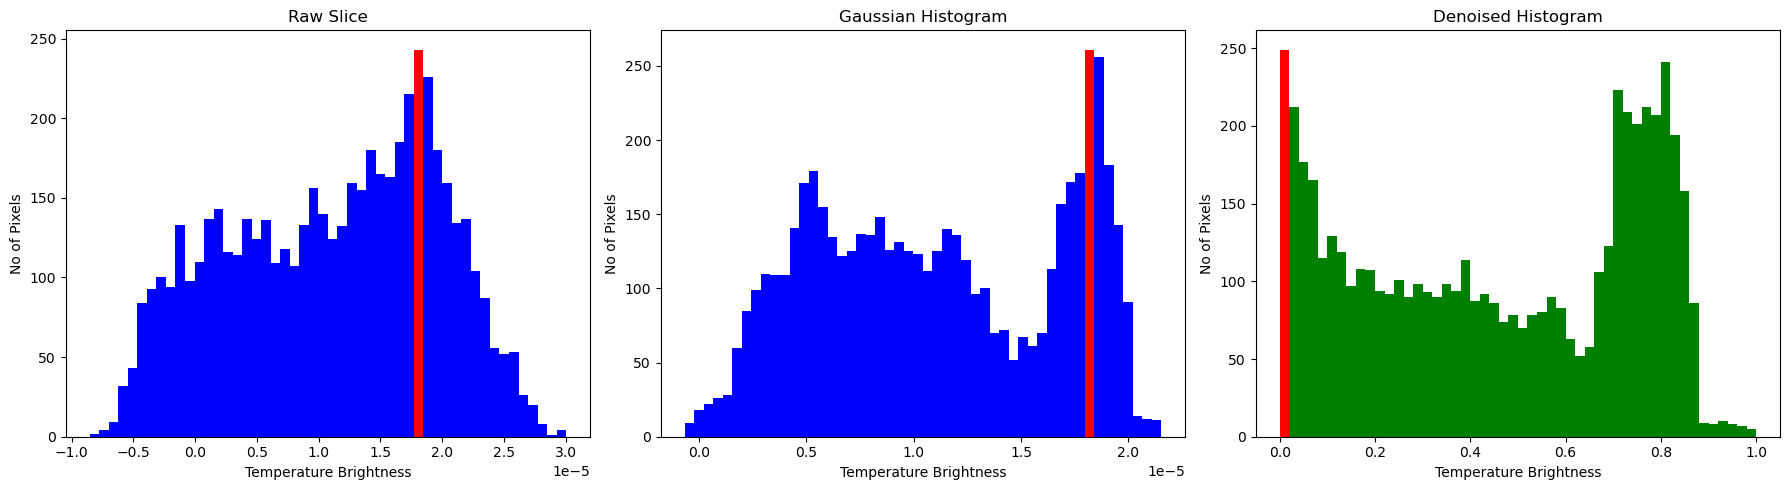

In [ ]:
# List of images and details
images = [cosmo_2, smoothed_image2, denoised_img_norm2]
titles = ["Raw Slice", "Gaussian Histogram", "Denoised Histogram"]
colors = ['blue', 'blue', 'green']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))

for i in range(3):
    data = images[i].flatten()
    counts, bins = np.histogram(data, bins=50)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    peak_idx = np.argmax(counts)

    # Set bar colors: highlight peak
    bar_colors = [colors[i]] * len(counts)
    bar_colors[peak_idx] = 'red'

    # Plot histogram with peak highlighted
    axes[i].bar(bin_centers, counts, width=np.diff(bins), color=bar_colors, align='center')
    axes[i].set_title(titles[i])
    axes[i].set_xlabel("Temperature Brightness")
    axes[i].set_ylabel("No of Pixels")

plt.tight_layout()
plt.savefig("Comparison_with_peaks.png", dpi=600, bbox_inches="tight")
plt.show()


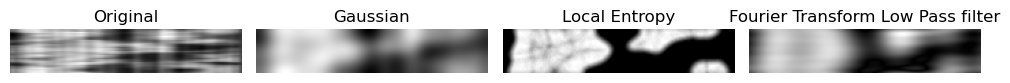

In [ ]:
import matplotlib.pyplot as plt

# Make sure these variables are already defined in your code:
# original_image, smoothed_image, entropy_map3, denoised_img_normE2, equalized2

fig, ax = plt.subplots(1, 4, figsize=(10, 10))  # ✅ 5 axes created

ax[0].imshow(cosmo_2, cmap='gray')
ax[0].set_title("Original")

ax[1].imshow(smoothed_image2, cmap='gray')
ax[1].set_title("Gaussian")

ax[2].imshow(entropy_map2, cmap='gray')
ax[2].set_title("Local Entropy")

ax[3].imshow(denoised_img_norm2, cmap='gray')
ax[3].set_title("Fourier Transform Low Pass filter")


for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()




### Local/adaptive thresholding
Compute a spatially varying threshold using a neighbourhood window. Check that `block_size` is odd and appropriate for the image dimensions, and record the offset because it changes the classified area.


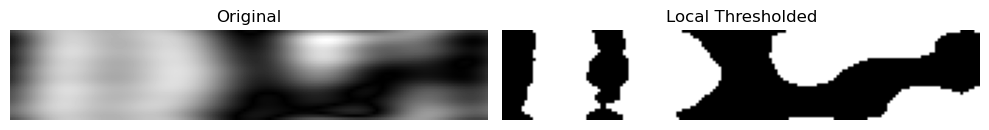

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_local
from skimage import io



# Set block size for local thresholding (must be odd)
block_size = 101  # you can experiment with values like 31, 51, 101
offset = 0  # adjust if needed to shift the threshold

# Compute the local threshold map
local_thresh = threshold_local(denoised_img_norm2, block_size, offset=offset)


# Apply threshold: pixels > local threshold → foreground (True)
binary_local25 = denoised_img_norm2 > local_thresh

# Plot original and thresholded image
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
plt.gray()

ax[0].imshow( denoised_img_norm2, cmap='gray')
ax[0].set_title("Original")

ax[1].imshow(binary_local25)
ax[1].set_title("Local Thresholded")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()


........................................................................................................................................................

Technique 2 is applied to corrupted images

........................................................................................................................................................

### Gaussian smoothing
Apply Gaussian convolution to suppress small-scale fluctuations. The `sigma` parameter controls the smoothing scale; stronger smoothing can also erase genuine small structures.


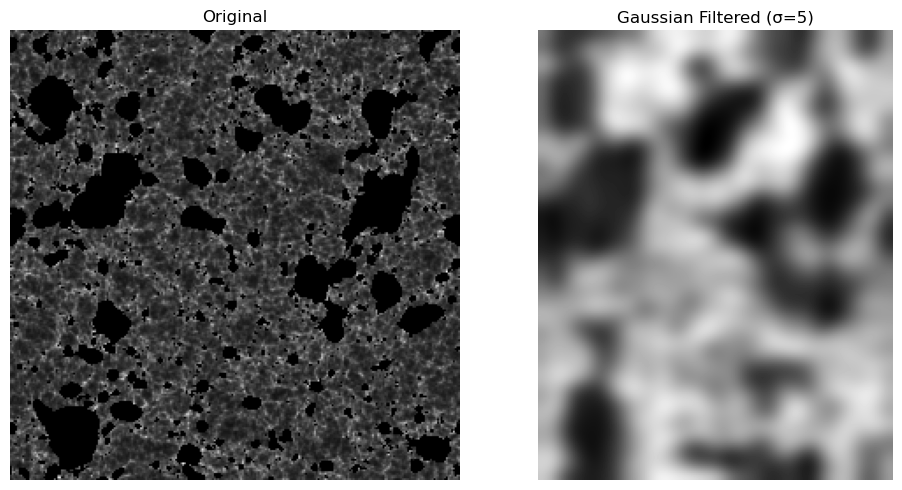

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage import data, img_as_float

# Load a sample image (you can replace this with your own image)
image3 = cosmo_3 # grayscale image

# Apply Gaussian filter
sigma = 5  # standard deviation, controls amount of blur
smoothed_image3 = gaussian_filter(image3, sigma=sigma)

# Display
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image1, cmap='grey')
axes[0].set_title("Original")
axes[1].imshow(smoothed_image3, cmap='grey')
axes[1].set_title(f"Gaussian Filtered (σ={sigma})")

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()


### Local entropy enhancement
Calculate neighbourhood entropy using a disk-shaped footprint. This measures local texture/variation, not ionization directly; intensity rescaling and footprint radius affect the result.


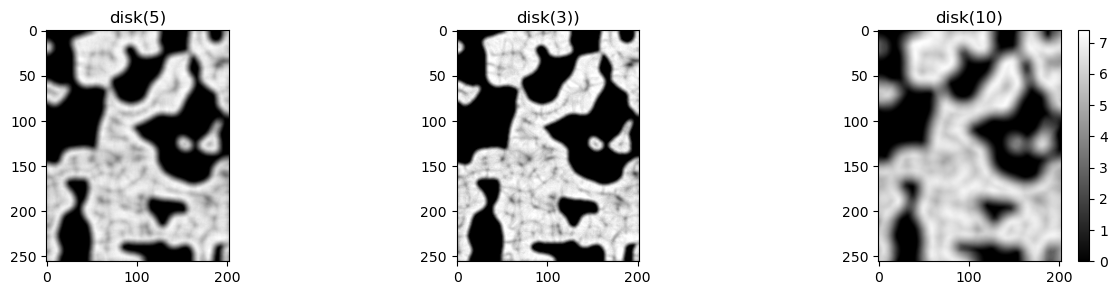

In [ ]:
import numpy as np

from skimage.filters.rank import entropy
from skimage.morphology import disk
from skimage import exposure
from skimage.util import img_as_ubyte

Cosmo_Entropy = img_as_ubyte(exposure.rescale_intensity(smoothed_image3))
entropy_map1 = entropy(Cosmo_Entropy, disk(5))
entropy_map2 = entropy(Cosmo_Entropy, disk(3))
entropy_map3 = entropy(Cosmo_Entropy, disk(10))
plt.figure(figsize= (15,3))


plt.subplot(1,3,1); plt.imshow(entropy_map1, cmap='gray')
plt.title("disk(5)")
plt.subplot(1,3,2); plt.imshow(entropy_map2, cmap='gray')
plt.title("disk(3))")
plt.subplot(1,3,3); plt.imshow(entropy_map3,cmap='gray')
plt.title("disk(10)")

plt.colorbar()

plt.show()

### Fourier-domain filtering
Transform the image to Fourier space, apply a low-pass mask, and transform back. The cutoff/radius determines which spatial frequencies are retained; document it as a filtering choice, not guaranteed foreground removal.


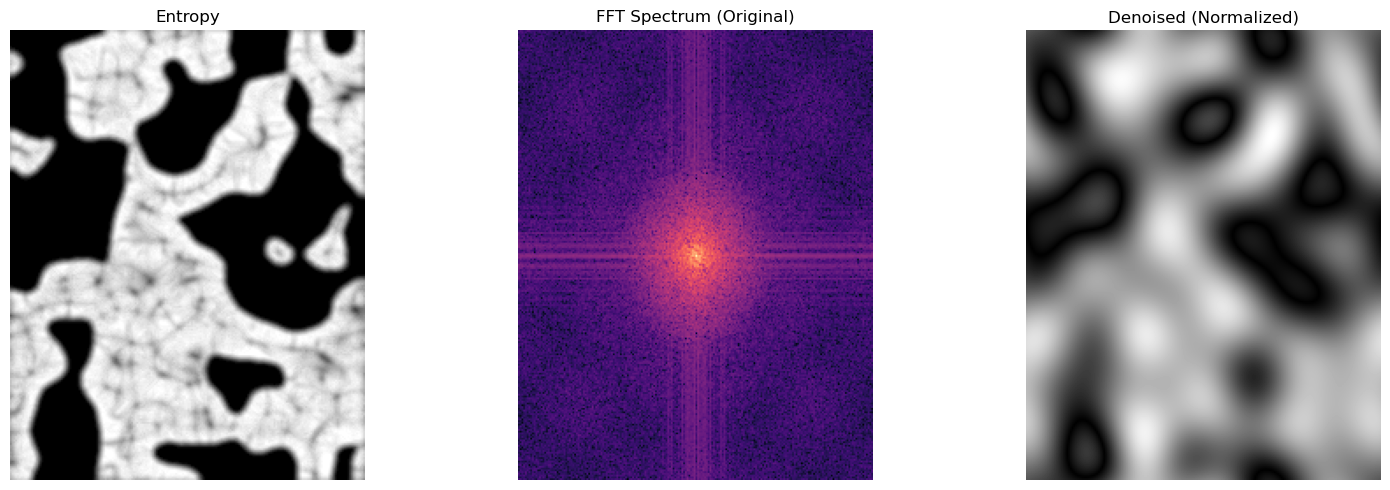

In [ ]:
# FFT FOR ENTROPY

import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft2, ifft2, fftshift, ifftshift
from skimage.util import invert
from skimage.exposure import rescale_intensity

def fft_low_pass_filter(entropy_map2, radius=20):
    # Step 1: Forward 2D FFT
    f_image = fft2(entropy_map2)
    f_shift = fftshift(f_image)  # Shift zero-freq to center

    # Step 2: Create circular low-pass filter mask
    rows, cols = entropy_map3.shape  # ✅ Fix here
    crow, ccol = rows // 2, cols // 2
    y, x = np.ogrid[:rows, :cols]
    mask_area = (x - ccol)**2 + (y - crow)**2 <= radius**2
    mask = np.zeros_like(entropy_map2)
    mask[mask_area] = 1

    # Step 3: Apply mask
    f_filtered = f_shift * mask

    # Step 4: Inverse FFT to get denoised image
    f_ishift = ifftshift(f_filtered)
    denoised = np.abs(ifft2(f_ishift))

    return denoised, f_shift, f_filtered

# ---- Step 1: Apply FFT Filter ----
denoised_img, fft_original, fft_filtered = fft_low_pass_filter(entropy_map2, radius=5)

# ---- Step 2: Normalize and Invert ----
denoised_img_norm3 = rescale_intensity(denoised_img, in_range='image', out_range=(0, 1))
inverted_img2 = invert(denoised_img_norm2)  # ✅ Fix here

# ---- Step 3: Plot All Results ----
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(entropy_map2, cmap='gray')
plt.title("Entropy")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(fft_original)), cmap='magma')
plt.title("FFT Spectrum (Original)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(denoised_img_norm3, cmap='gray')
plt.title("Denoised (Normalized)")
plt.axis('off')

plt.tight_layout()
plt.show()


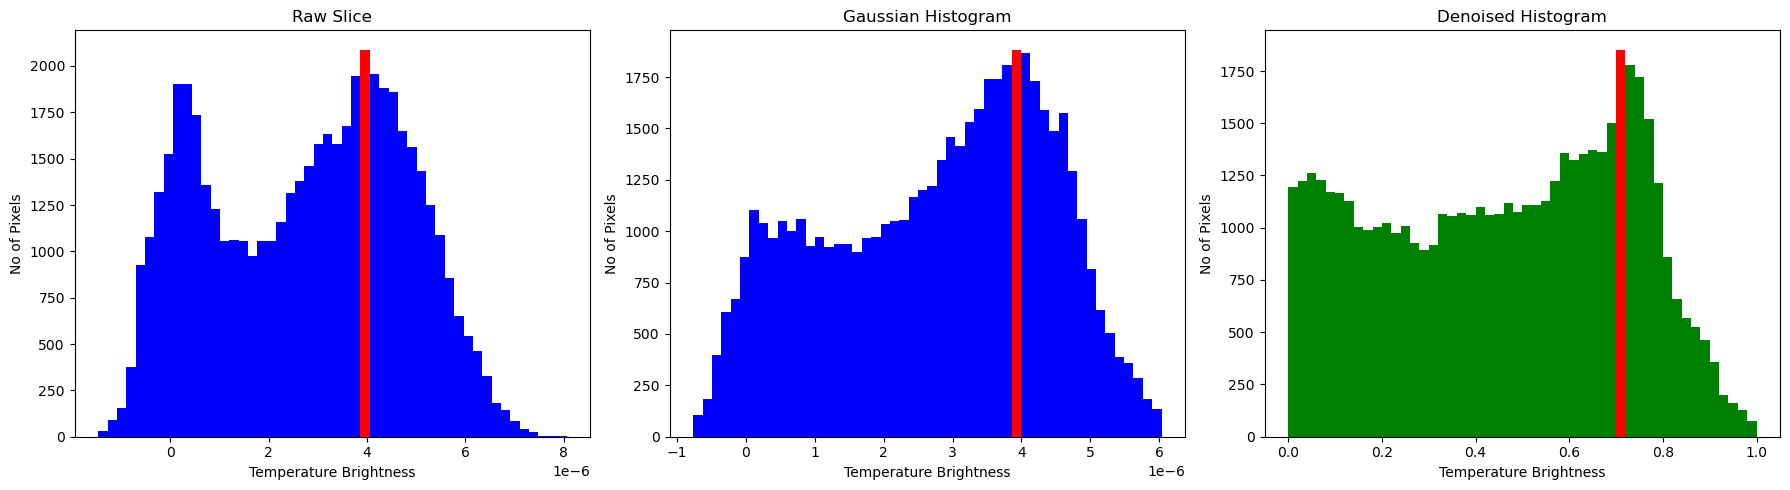

In [ ]:
# List of images and details
images = [cosmo_3, smoothed_image3, denoised_img_norm3]
titles = ["Raw Slice", "Gaussian Histogram", "Denoised Histogram"]
colors = ['blue', 'blue', 'green']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))

for i in range(3):
    data = images[i].flatten()
    counts, bins = np.histogram(data, bins=50)
    bin_centers = (bins[:-1] + bins[1:]) / 2
    peak_idx = np.argmax(counts)

    # Set bar colors: highlight peak
    bar_colors = [colors[i]] * len(counts)
    bar_colors[peak_idx] = 'red'

    # Plot histogram with peak highlighted
    axes[i].bar(bin_centers, counts, width=np.diff(bins), color=bar_colors, align='center')
    axes[i].set_title(titles[i])
    axes[i].set_xlabel("Temperature Brightness")
    axes[i].set_ylabel("No of Pixels")

plt.tight_layout()
plt.savefig("Comparison_with_peaks.png", dpi=600, bbox_inches="tight")
plt.show()


### Local/adaptive thresholding
Compute a spatially varying threshold using a neighbourhood window. Check that `block_size` is odd and appropriate for the image dimensions, and record the offset because it changes the classified area.


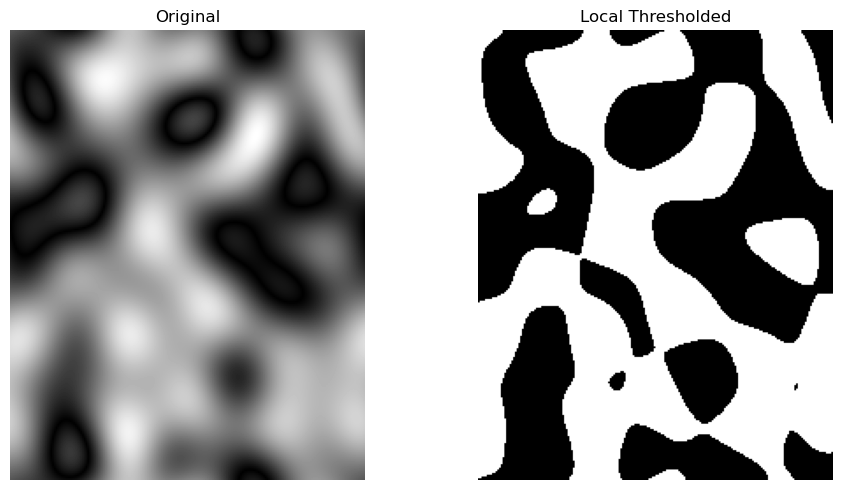

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_local
from skimage import io



# Set block size for local thresholding (must be odd)
block_size = 101  # you can experiment with values like 31, 51, 101
offset = 0  # adjust if needed to shift the threshold

# Compute the local threshold map
local_thresh = threshold_local(denoised_img_norm3, block_size, offset=offset)


# Apply threshold: pixels > local threshold → foreground (True)
binary_local26 = denoised_img_norm3 > local_thresh

# Plot original and thresholded image
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
plt.gray()

ax[0].imshow( denoised_img_norm3 , cmap='gray')
ax[0].set_title("Original")

ax[1].imshow(binary_local26)
ax[1].set_title("Local Thresholded")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()


DIRECTLY APPLYING LOCAL THRESHOLDING WITHOUT PASSING THROUGH LOW PASS FILTER

### Local/adaptive thresholding
Compute a spatially varying threshold using a neighbourhood window. Check that `block_size` is odd and appropriate for the image dimensions, and record the offset because it changes the classified area.


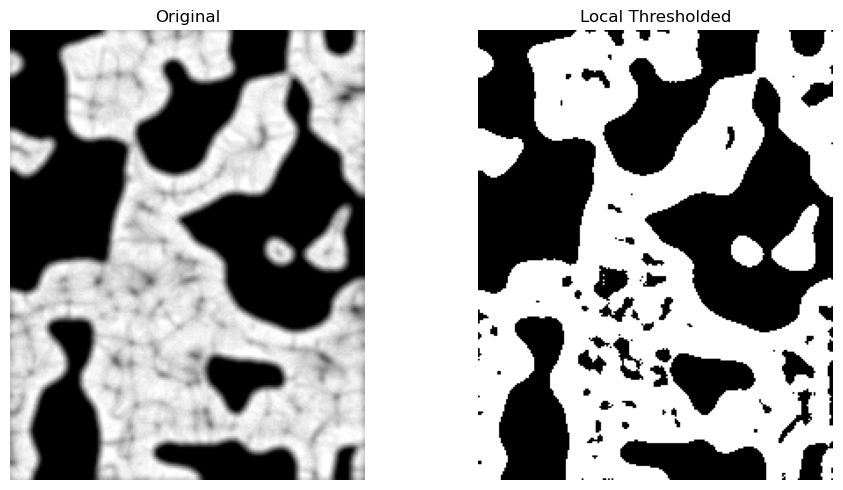

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_local
from skimage import io



# Set block size for local thresholding (must be odd)
block_size = 101  # you can experiment with values like 31, 51, 101
offset = 0  # adjust if needed to shift the threshold

# Compute the local threshold map
local_thresh = threshold_local(entropy_map2, block_size, offset=offset)


# Apply threshold: pixels > local threshold → foreground (True)
binary_local = entropy_map2 > local_thresh

# Plot original and thresholded image
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
plt.gray()

ax[0].imshow( entropy_map2 , cmap='gray')
ax[0].set_title("Original")

ax[1].imshow(binary_local)
ax[1].set_title("Local Thresholded")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
......................................................................................................................................................

Watershed with markers Method

In [ ]:
........................................................................................................................................................

Original Image

### Watershed / region-based segmentation
Use the binary mask and distance/topographic representation to assign region labels. Verify foreground polarity explicitly: the mask supplied to watershed must represent the structures intended for partitioning. This experiment is retained even where results are limited.


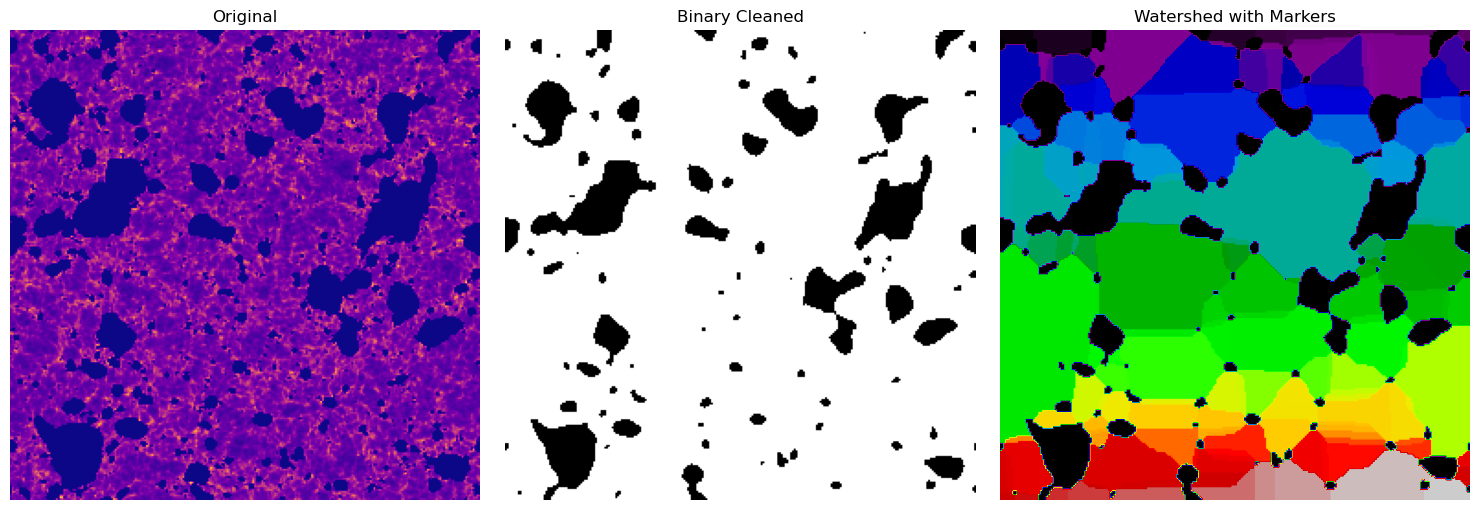

In [ ]:
from skimage.segmentation import watershed
from skimage.feature import peak_local_max
from skimage.morphology import remove_small_objects, local_maxima
from skimage.measure import label
from scipy import ndimage as ndi
import matplotlib.pyplot as plt

# Step 1: Clean binary mask
binary_clean = remove_small_objects(sharpened1.astype(bool), min_size=50)

# Step 2: Distance transform
distance = ndi.distance_transform_edt(binary_clean)

# Step 3: Local maxima mask
local_maxi = local_maxima(distance * binary_clean)

# Step 4: Label foreground markers
markers = label(local_maxi)

# Step 5: Apply watershed
labels_ws = watershed(-distance, markers, mask=binary_clean)

# Step 6: Display results
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(cosmo_1, cmap='plasma')
ax[0].set_title('Original')

ax[1].imshow(binary_clean, cmap='gray')
ax[1].set_title('Binary Cleaned')

ax[2].imshow(labels_ws, cmap='nipy_spectral')
ax[2].set_title('Watershed with Markers')

for a in ax:
    a.set_axis_off()

plt.tight_layout()
plt.show()


### Watershed / region-based segmentation
Use the binary mask and distance/topographic representation to assign region labels. Verify foreground polarity explicitly: the mask supplied to watershed must represent the structures intended for partitioning. This experiment is retained even where results are limited.


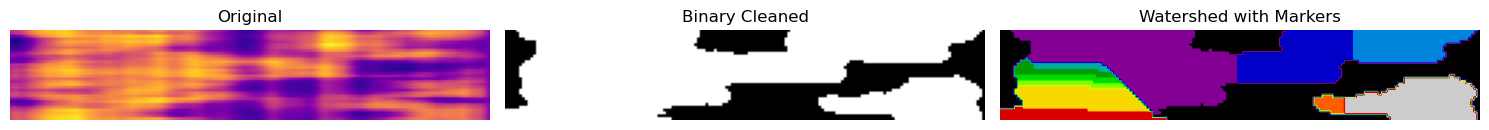

In [ ]:
from skimage.segmentation import watershed
from skimage.feature import peak_local_max
from skimage.morphology import remove_small_objects, local_maxima
from skimage.measure import label
from scipy import ndimage as ndi
import matplotlib.pyplot as plt

# Step 1: Clean binary mask
binary_clean = remove_small_objects(sharpened2.astype(bool), min_size=50)

# Step 2: Distance transform
distance = ndi.distance_transform_edt(binary_clean)

# Step 3: Local maxima mask
local_maxi = local_maxima(distance * binary_clean)

# Step 4: Label foreground markers
markers = label(local_maxi)

# Step 5: Apply watershed
labels_ws = watershed(-distance, markers, mask=binary_clean)

# Step 6: Display results
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(cosmo_2, cmap='plasma')
ax[0].set_title('Original')

ax[1].imshow(binary_clean, cmap='gray')
ax[1].set_title('Binary Cleaned')

ax[2].imshow(labels_ws, cmap='nipy_spectral')
ax[2].set_title('Watershed with Markers')

for a in ax:
    a.set_axis_off()

plt.tight_layout()
plt.show()


### Watershed / region-based segmentation
Use the binary mask and distance/topographic representation to assign region labels. Verify foreground polarity explicitly: the mask supplied to watershed must represent the structures intended for partitioning. This experiment is retained even where results are limited.


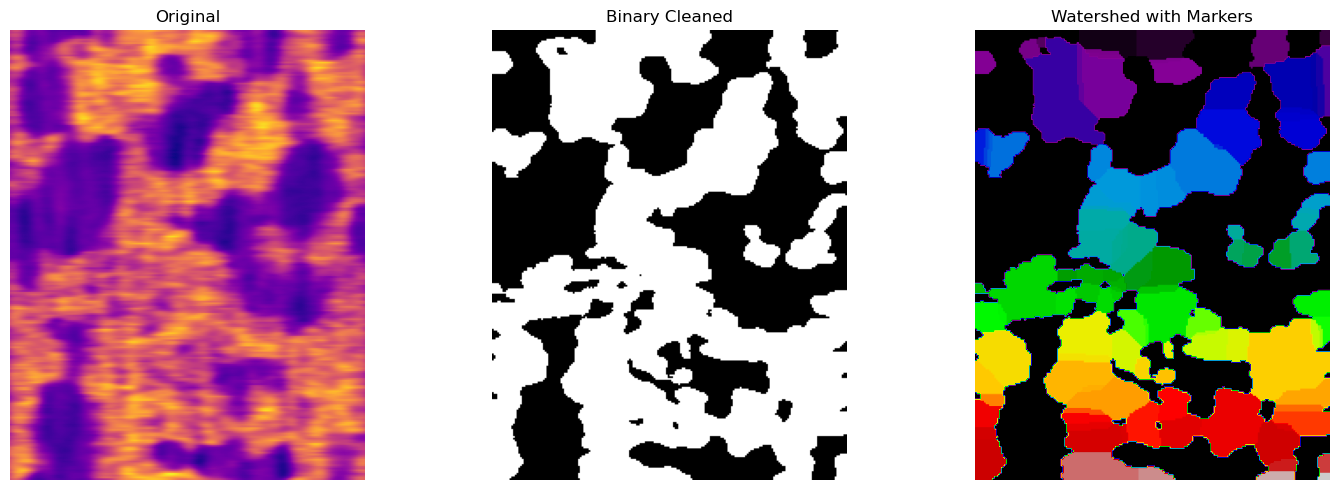

In [ ]:
from skimage.segmentation import watershed
from skimage.feature import peak_local_max
from skimage.morphology import remove_small_objects, local_maxima
from skimage.measure import label
from scipy import ndimage as ndi
import matplotlib.pyplot as plt

# Step 1: Clean binary mask
binary_clean = remove_small_objects(sharpened3.astype(bool), min_size=50)

# Step 2: Distance transform
distance = ndi.distance_transform_edt(binary_clean)

# Step 3: Local maxima mask
local_maxi = local_maxima(distance * binary_clean)

# Step 4: Label foreground markers
markers = label(local_maxi)

# Step 5: Apply watershed
labels_ws = watershed(-distance, markers, mask=binary_clean)

# Step 6: Display results
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(cosmo_3, cmap='plasma')
ax[0].set_title('Original')

ax[1].imshow(binary_clean, cmap='gray')
ax[1].set_title('Binary Cleaned')

ax[2].imshow(labels_ws, cmap='nipy_spectral')
ax[2].set_title('Watershed with Markers')

for a in ax:
    a.set_axis_off()

plt.tight_layout()
plt.show()


COMPARISON OF THE METHODS :

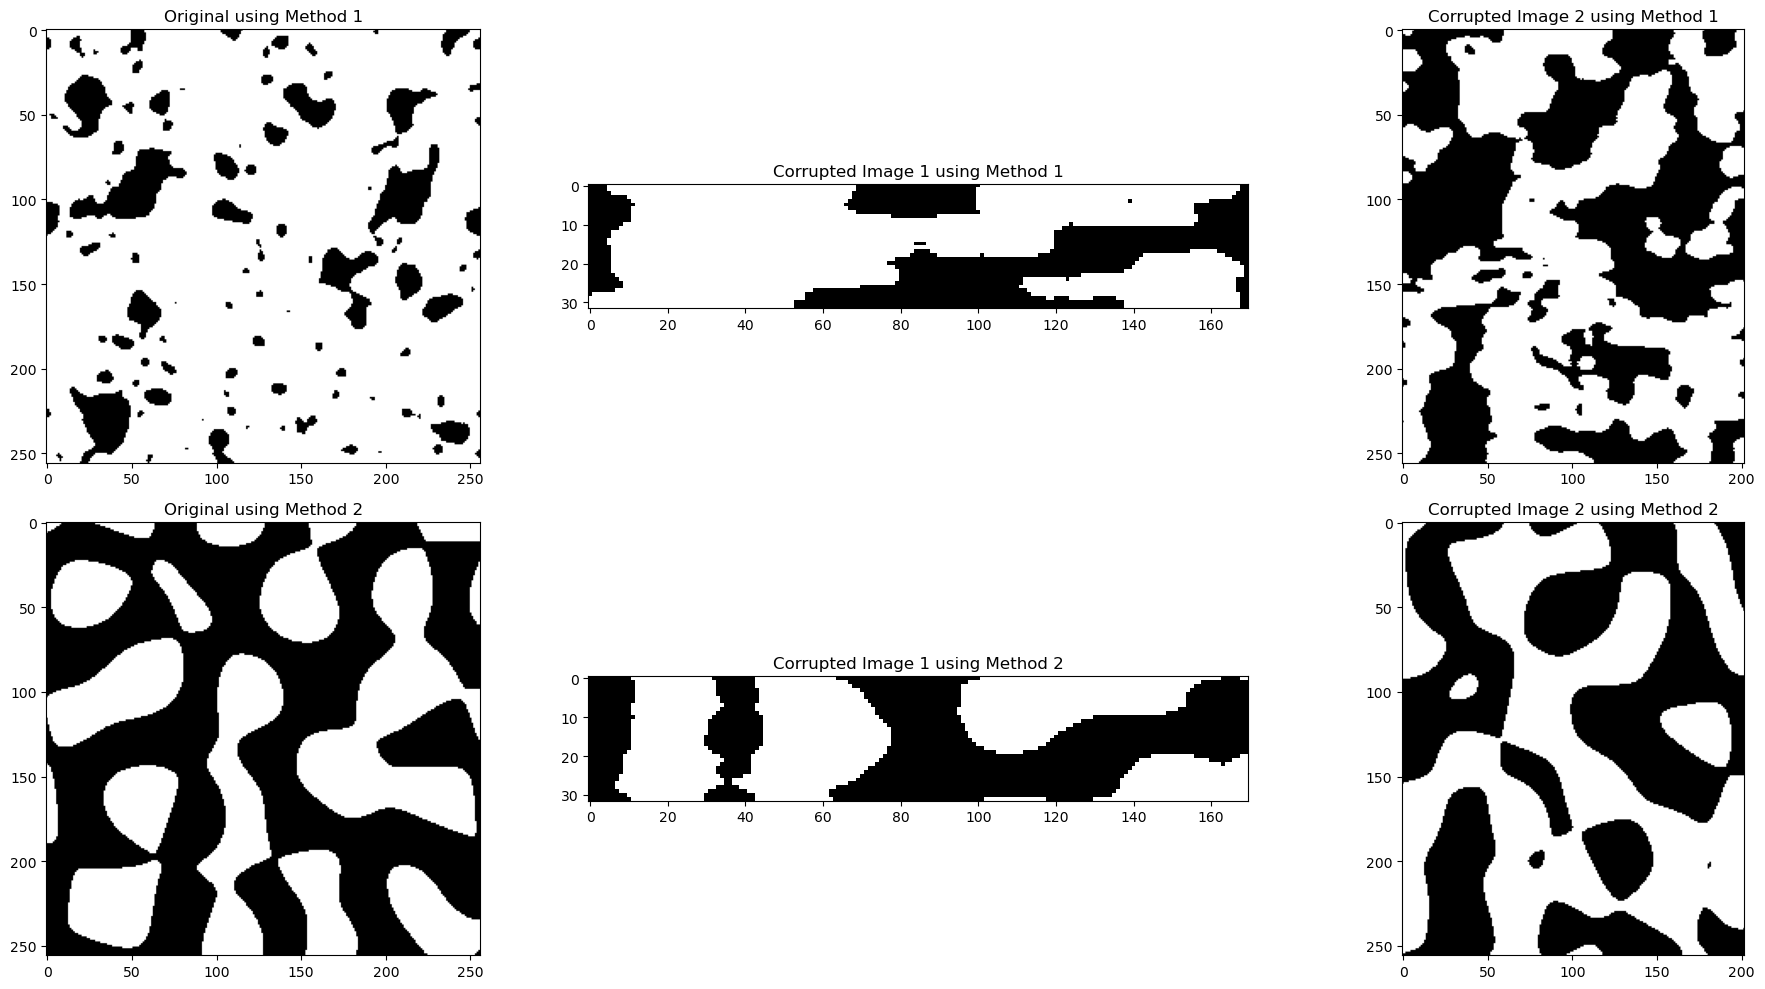

In [ ]:
import matplotlib.pyplot as plt
import numpy as np # Assuming binary_local21, etc., are NumPy arrays

# Create subplots with 2 rows and 3 columns
fig, ax = plt.subplots(2, 3, figsize=(20, 10)) # Increased figsize height for better viewing

# Plot your images
# Row 0
ax[0, 0].imshow(binary_local21, cmap='gray')
ax[0, 0].set_title("Original using Method 1")

ax[0, 1].imshow(binary_local22, cmap='gray')
ax[0, 1].set_title("Corrupted Image 1 using Method 1")

ax[0, 2].imshow(binary_local23, cmap='gray')
ax[0, 2].set_title("Corrupted Image 2 using Method 1")

# Row 1
ax[1, 0].imshow(binary_local24, cmap='gray')
ax[1, 0].set_title("Original using Method 2")

ax[1, 1].imshow(binary_local25, cmap='gray')
ax[1, 1].set_title("Corrupted Image 1 using Method 2")

ax[1, 2].imshow(binary_local26, cmap='gray')
ax[1, 2].set_title("Corrupted Image 2 using Method 2")

# Use plt.tight_layout() before plt.show() for optimal spacing
plt.tight_layout()
plt.show()


for a in ax.flat: # Use .flat to iterate over all axes in the 2D array
    a.axis('off')



### Watershed / region-based segmentation
Use the binary mask and distance/topographic representation to assign region labels. Verify foreground polarity explicitly: the mask supplied to watershed must represent the structures intended for partitioning. This experiment is retained even where results are limited.


In [ ]:
from skimage.segmentation import watershed
from skimage.feature import peak_local_max
from skimage.morphology import remove_small_objects, local_maxima
from skimage.measure import label
from scipy import ndimage as ndi
import matplotlib.pyplot as plt

# Step 1: Clean binary mask
binary_clean = remove_small_objects(sharpened.astype(bool), min_size=50)

# Step 2: Distance transform
distance = ndi.distance_transform_edt(binary_clean)

# Step 3: Local maxima mask
local_maxi = local_maxima(distance * binary_clean)

# Step 4: Label foreground markers
markers = label(local_maxi)

# Step 5: Apply watershed
labels_ws = watershed(-distance, markers, mask=binary_clean)

# Step 6: Display results
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(cosmo_2d, cmap='plasma')
ax[0].set_title('Original')

ax[1].imshow(binary_clean, cmap='gray')
ax[1].set_title('Binary Cleaned')

ax[2].imshow(labels_ws, cmap='nipy_spectral')
ax[2].set_title('Watershed with Markers')

for a in ax:
    a.set_axis_off()

plt.tight_layout()
plt.show()
